# 03 · Patrones espaciales, elección de microzona y contraste de HE2

**Entrada:** `datos/incidencias_limpias.csv`, límite INEI 150133. **CRS métrico:** UTM 18S (EPSG:32718).
**Salidas:** `datos/microzonas.geojson` (WGS84, `MZ-0001`…), columnas `mz_col`, `mz_fila`, `id_microzona` añadidas al dataset limpio,
`datos/metricas_espacial.json`.

Reglas: las **celdas activas** y los umbrales se calculan **solo con entrenamiento** (22–31 may). Las estadísticas de comparación y HE2 usan
entrenamiento + validación (22 may – 4 jun). El periodo de prueba (5–8 jun) no se usa.
No se usa H3 (la librería no forma parte del entorno del proyecto); se evalúan grillas cuadradas de 300, 500, 750 y 1 000 m.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from shapely.geometry import mapping
from _comun import *

configurar_estilo()
np.random.seed(SEMILLA)
pd.set_option("display.width", 160)

df = cargar_limpias()
poligono = limite_metrico()
TR_INI, TR_FIN = PARTICION["train"]
VA_INI, VA_FIN = PARTICION["valid"]
fechas_train = fechas_rango(TR_INI, TR_FIN)
fechas_tv = fechas_rango(TR_INI, VA_FIN)
train = df[(df.fecha >= TR_INI) & (df.fecha <= TR_FIN)]
tv = df[(df.fecha >= TR_INI) & (df.fecha <= VA_FIN)]
print(f"Entrenamiento: {len(train)} registros en {len(fechas_train)} días · entrenamiento+validación: {len(tv)} en {len(fechas_tv)} días")

Entrenamiento: 1143 registros en 10 días · entrenamiento+validación: 1602 en 14 días


## 1. Comparación de microzonas candidatas
Para cada tamaño: celdas que intersecan el distrito, celdas activas (≥ 1 incidencia en entrenamiento), % de celdas-turno con cero,
media y mediana del conteo por celda-turno, y balance de clases que resultaría con la regla del objetivo
(Bajo = 0; Medio = 1…b; Alto > b; b = mediana de los conteos positivos de entrenamiento).

In [2]:
def tabla_conteos(datos, celdas_activas, fechas, tam, org):
    col, fila = celda_de(datos.x_utm, datos.y_utm, tam, org)
    d = datos.assign(celda=list(zip(col, fila)))
    d = d[d.celda.isin(celdas_activas)]
    idx = pd.MultiIndex.from_product([sorted(celdas_activas), fechas, TURNOS], names=["celda", "fecha", "turno"])
    return d.groupby(["celda", "fecha", "turno"]).size().reindex(idx, fill_value=0)

filas, conteos_por_tam = [], {}
for tam in [300, 500, 750, 1000]:
    org = origen_grilla(tam, poligono)
    inter = celdas_que_intersecan(tam, org, poligono)
    set_inter = set(zip(inter.col, inter.fila))
    c_tr, f_tr = celda_de(train.x_utm, train.y_utm, tam, org)
    activas = set(zip(c_tr, f_tr)) & set_inter
    y_tr = tabla_conteos(train, activas, fechas_train, tam, org)
    y_tv = tabla_conteos(tv, activas, fechas_tv, tam, org)
    pos = y_tr[y_tr > 0]
    b = float(np.median(pos))
    clases_tr = pd.cut(y_tr, [-0.5, 0.5, b + 0.5, np.inf], labels=NIVELES).value_counts(normalize=True).reindex(NIVELES) * 100
    c_tv, f_tv = celda_de(tv.x_utm, tv.y_utm, tam, org)
    cobertura = np.mean([c in activas for c in zip(c_tv, f_tv)]) * 100
    conteos_por_tam[tam] = (org, inter, activas, y_tv)
    filas.append({"tamano_m": tam, "area_km2": tam ** 2 / 1e6, "celdas_distrito": len(set_inter), "n_activas": len(activas),
                  "filas_tabla_tv": len(y_tv), "pct_ceros": round(float((y_tv == 0).mean() * 100), 1),
                  "media": round(float(y_tv.mean()), 2), "mediana": float(y_tv.median()),
                  "media_positivos": round(float(y_tv[y_tv > 0].mean()), 2), "b_umbral": b,
                  "pct_bajo_train": round(float(clases_tr["Bajo"]), 1), "pct_medio_train": round(float(clases_tr["Medio"]), 1),
                  "pct_alto_train": round(float(clases_tr["Alto"]), 1), "cobertura_tv_pct": round(float(cobertura), 1)})
comparacion = pd.DataFrame(filas)
print(comparacion.to_string(index=False))

 tamano_m  area_km2  celdas_distrito  n_activas  filas_tabla_tv  pct_ceros  media  mediana  media_positivos  b_umbral  pct_bajo_train  pct_medio_train  pct_alto_train  cobertura_tv_pct
      300    0.0900              307        176            7392       84.7   0.21      0.0             1.39       1.0            84.3             12.1             3.6              98.1
      500    0.2500              121         86            3612       72.4   0.44      0.0             1.60       1.0            72.0             18.6             9.4              99.5
      750    0.5625               64         45            1890       58.1   0.85      0.0             2.02       1.0            57.7             22.6            19.7             100.0
     1000    1.0000               38         30            1260       50.8   1.27      0.0             2.58       2.0            50.7             32.4            16.9              99.9


### Criterios de elección (fijados antes de elegir)
(a) **Señal para tres niveles:** en entrenamiento, Alto ≥ 5 % y Medio ≥ 10 % de las celdas-turno.
(b) **Tamaño interpretable para un operador:** lado ≤ 500 m (≈ 5 cuadras de ~100 m; se recorre a pie en ~6 minutos), del orden de un
    conjunto de manzanas y no de un barrio entero.
(c) **Número manejable de celdas:** entre 30 y 150 microzonas activas (un ranking legible por turno).
(d) **Cobertura:** ≥ 95 % de los registros de entrenamiento + validación caen en celdas activas.

In [3]:
comparacion["a_senal"] = (comparacion.pct_alto_train >= 5) & (comparacion.pct_medio_train >= 10)
comparacion["b_interpretable"] = comparacion.tamano_m <= 500
comparacion["c_manejable"] = comparacion.n_activas.between(30, 150)
comparacion["d_cobertura"] = comparacion.cobertura_tv_pct >= 95
comparacion["cumple_todo"] = comparacion[["a_senal", "b_interpretable", "c_manejable", "d_cobertura"]].all(axis=1)
print(comparacion[["tamano_m", "n_activas", "pct_ceros", "pct_alto_train", "cobertura_tv_pct",
                   "a_senal", "b_interpretable", "c_manejable", "d_cobertura", "cumple_todo"]].to_string(index=False))
elegida = comparacion[comparacion.cumple_todo]
assert len(elegida) == 1, "Los criterios deben dejar exactamente una opción"
TAM = int(elegida.tamano_m.iloc[0])
print(f"\nMicrozona elegida: grilla de {TAM} m")

 tamano_m  n_activas  pct_ceros  pct_alto_train  cobertura_tv_pct  a_senal  b_interpretable  c_manejable  d_cobertura  cumple_todo
      300        176       84.7             3.6              98.1    False             True        False         True        False
      500         86       72.4             9.4              99.5     True             True         True         True         True
      750         45       58.1            19.7             100.0     True            False         True         True        False
     1000         30       50.8            16.9              99.9     True            False         True         True        False

Microzona elegida: grilla de 500 m


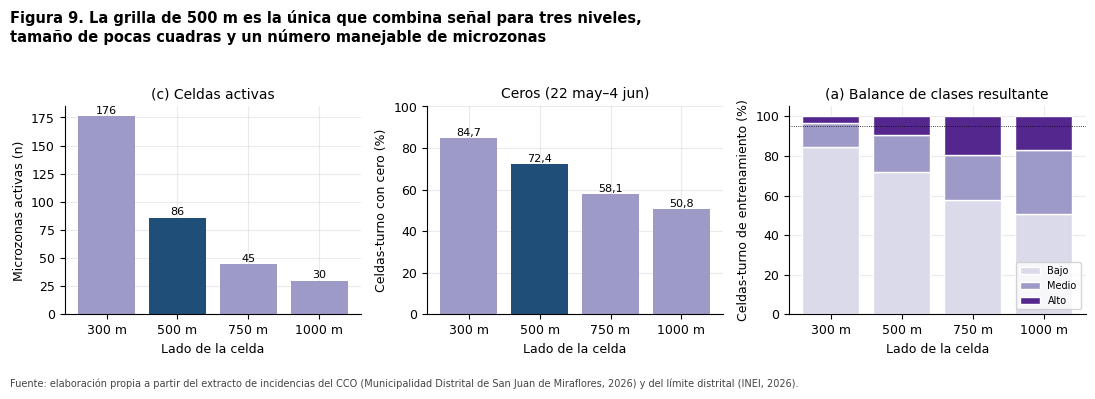

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig09_comparacion_grillas.png')

In [4]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(11, 3.9))
etq = [f"{t} m" for t in comparacion.tamano_m]
colores = [AZUL if t == TAM else "#9E9AC8" for t in comparacion.tamano_m]
a1.bar(etq, comparacion.n_activas, color=colores); a1.set_ylabel("Microzonas activas (n)"); a1.set_title("(c) Celdas activas")
for i, v in enumerate(comparacion.n_activas): a1.text(i, v + 2, fmt(v), ha="center", fontsize=8)
a2.bar(etq, comparacion.pct_ceros, color=colores); a2.set_ylabel("Celdas-turno con cero (%)"); a2.set_title("Ceros (22 may–4 jun)")
for i, v in enumerate(comparacion.pct_ceros): a2.text(i, v + 1, fmt(v, 1), ha="center", fontsize=8)
a2.set_ylim(0, 100)
izq = np.zeros(len(comparacion))
for n in NIVELES:
    vals = comparacion[f"pct_{n.lower()}_train"].values
    a3.bar(etq, vals, bottom=izq, color=COLOR_NIVEL[n], label=n, edgecolor="white")
    izq += vals
a3.axhline(100 - 5, color="k", lw=0.6, ls=":")
a3.set_ylabel("Celdas-turno de entrenamiento (%)"); a3.set_title("(a) Balance de clases resultante"); a3.legend(fontsize=7, loc="lower right")
for ax in (a1, a2, a3):
    ax.set_xlabel("Lado de la celda"); eje_es(ax, "y", 0)
guardar_figura(fig, "fig09_comparacion_grillas.png", 9,
               f"La grilla de {TAM} m es la única que combina señal para tres niveles,\ntamaño de pocas cuadras y un número manejable de microzonas",
               FUENTE_CCO_LIMITE)

## 2. Microzonas activas y exportación
**Criterio de activa:** celda de la grilla elegida que interseca el límite distrital y tiene ≥ 1 incidencia limpia (dentro del límite o a ≤ 150 m)
registrada entre el 22 y el 31 de mayo (entrenamiento). Identificador estable: `MZ-0001`… ordenado de norte a sur (fila descendente) y de oeste a este (columna ascendente).

In [5]:
org, inter, activas, y_tv = conteos_por_tam[TAM]
inter = inter.copy()
inter["activa"] = [(c, f) in activas for c, f in zip(inter.col, inter.fila)]
act = inter[inter.activa].sort_values(["fila", "col"], ascending=[False, True]).reset_index(drop=True)
act["id_microzona"] = [f"MZ-{i + 1:04d}" for i in range(len(act))]
features = []
for _, r in act.iterrows():
    g = a_wgs84(r.geom)
    cen = g.centroid
    features.append({"type": "Feature", "geometry": mapping(g), "properties": {
        "id_microzona": r.id_microzona, "col": int(r.col), "fila": int(r.fila), "tamano_m": TAM,
        "x_min_utm": org[0] + r.col * TAM, "y_min_utm": org[1] + r.fila * TAM,
        "lon_centro": round(cen.x, 6), "lat_centro": round(cen.y, 6),
        "pct_area_dentro_distrito": round(float(r.frac_dentro * 100), 1)}})
geo = {"type": "FeatureCollection", "name": f"microzonas_sjm_{TAM}m",
       "crs": {"type": "name", "properties": {"name": "urn:ogc:def:crs:OGC:1.3:CRS84"}},
       "metadatos": {"crs_metrico": CRS_METRICO, "origen_grilla_utm": list(org), "tamano_m": TAM,
                     "criterio_activa": f"Celda de {TAM} m que interseca el límite INEI 150133 con ≥1 incidencia limpia entre {TR_INI} y {TR_FIN}",
                     "asignacion": "col = floor((x_utm - x0)/tamano); fila = floor((y_utm - y0)/tamano)"},
       "features": features}
(DATOS / "microzonas.geojson").write_text(json.dumps(geo, ensure_ascii=False), encoding="utf-8")
print(f"Microzonas activas: {len(act)} de {len(inter)} celdas que intersecan el distrito · origen UTM {org}")

# Columnas de microzona en el dataset limpio
df["mz_col"], df["mz_fila"] = celda_de(df.x_utm, df.y_utm, TAM, org)
mapa_id = {(r.col, r.fila): r.id_microzona for r in act.itertuples()}
df["id_microzona"] = [mapa_id.get((c, f)) for c, f in zip(df.mz_col, df.mz_fila)]
df.to_csv(DATOS / "incidencias_limpias.csv", index=False, encoding="utf-8")
sin_mz = df.id_microzona.isna()
print("Registros fuera de microzonas activas por periodo:", df[sin_mz].periodo.value_counts().to_dict())
print(f"Cobertura de entrenamiento: {fmt((~sin_mz[(df.fecha >= TR_INI) & (df.fecha <= TR_FIN)]).mean() * 100, 1)} % · "
      f"validación: {fmt((~sin_mz[(df.fecha >= VA_INI) & (df.fecha <= VA_FIN)]).mean() * 100, 1)} %")

Microzonas activas: 86 de 121 celdas que intersecan el distrito · origen UTM (283500.0, 8651000.0)
Registros fuera de microzonas activas por periodo: {'estable': 21, 'censurado': 7}
Cobertura de entrenamiento: 100,0 % · validación: 98,3 %


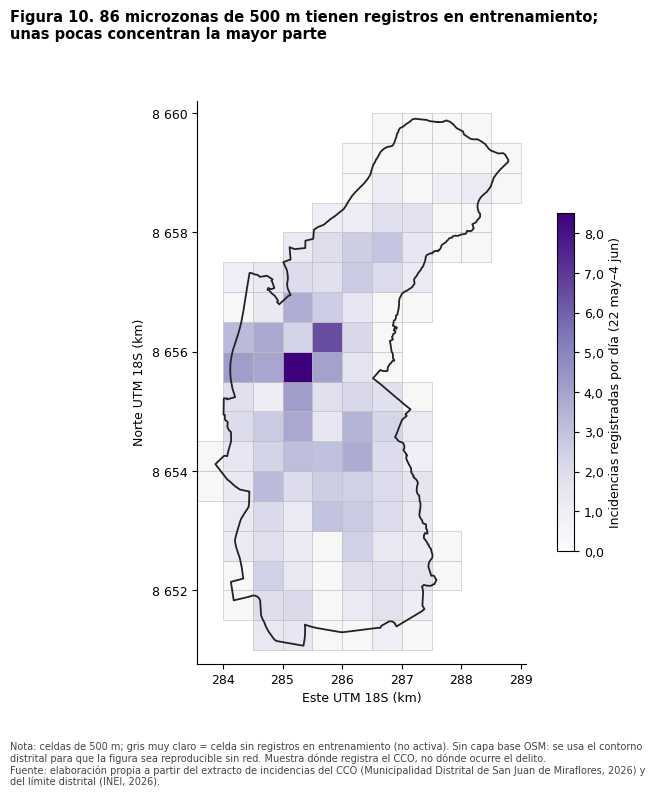

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig10_mapa_microzonas.png')

In [6]:
cnt_mz = tv.assign(celda=list(zip(*celda_de(tv.x_utm, tv.y_utm, TAM, org)))).groupby("celda").size()
fig, ax = plt.subplots(figsize=(6.6, 8))
norm = Normalize(0, (cnt_mz / len(fechas_tv)).max())
cmap = plt.get_cmap("Purples")
parches, colores_p = [], []
for _, r in inter.iterrows():
    xs, ys = r.geom.exterior.xy
    p = MplPolygon(np.c_[np.array(xs) / 1000, np.array(ys) / 1000], closed=True)
    v = cnt_mz.get((r.col, r.fila), 0) / len(fechas_tv)
    parches.append(p); colores_p.append(cmap(0.12 + 0.88 * norm(v)) if r.activa else "#F7F7F7")
pc = PatchCollection(parches, facecolor=colores_p, edgecolor="#BBBBBB", linewidth=0.4)
ax.add_collection(pc)
xb, yb = poligono.exterior.xy
ax.plot(np.array(xb) / 1000, np.array(yb) / 1000, color="#222222", lw=1.3)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.6); cb.set_label("Incidencias registradas por día (22 may–4 jun)")
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt(v, 1)))
ax.set_xlim(poligono.bounds[0] / 1000 - 0.3, poligono.bounds[2] / 1000 + 0.3)
ax.set_ylim(poligono.bounds[1] / 1000 - 0.3, poligono.bounds[3] / 1000 + 0.3)
ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("Este UTM 18S (km)"); ax.set_ylabel("Norte UTM 18S (km)"); eje_es(ax, "x", 0); eje_es(ax, "y", 0)
guardar_figura(fig, "fig10_mapa_microzonas.png", 10,
               f"{len(act)} microzonas de {TAM} m tienen registros en entrenamiento;\nunas pocas concentran la mayor parte",
               f"Nota: celdas de {TAM} m; gris muy claro = celda sin registros en entrenamiento (no activa). Sin capa base OSM: se usa el contorno\n"
               "distrital para que la figura sea reproducible sin red. Muestra dónde registra el CCO, no dónde ocurre el delito.\n"
               + FUENTE_CCO_LIMITE)

## 3. HE2: concentración espacial de los registros
**Hipótesis:** una fracción reducida de las microzonas acumula la mayor parte de los registros.
**Universo:** todas las celdas de la grilla que intersecan el distrito (incluidas las que no registran nada), ventana 22 may – 4 jun.
**Regla de decisión (fijada antes de calcular):** `se_sostiene` si (i) ≤ 20 % de las celdas acumula ≥ 50 % de los registros y (ii) el índice de
Gini ≥ 0,5, y ambas condiciones se cumplen también con 300 y 750 m y por separado en entrenamiento y en validación;
`no_se_sostiene` si (i) o (ii) fallan con la grilla elegida; `no_concluyente` en otro caso.

In [7]:
def concentracion(conteos: np.ndarray):
    x = np.sort(np.asarray(conteos, dtype=float))[::-1]
    n, total = len(x), x.sum()
    acum = np.cumsum(x) / total
    frac_celdas = np.arange(1, n + 1) / n
    p50 = frac_celdas[np.searchsorted(acum, 0.5)] * 100
    p80 = frac_celdas[np.searchsorted(acum, 0.8)] * 100
    xs = np.sort(x)
    gini = (2 * np.sum(np.arange(1, n + 1) * xs) / (n * xs.sum())) - (n + 1) / n
    return {"pct_celdas_50": round(float(p50), 1), "pct_celdas_80": round(float(p80), 1), "gini": round(float(gini), 3),
            "n_celdas": int(n), "registros": int(total), "pct_celdas_con_registro": round(float((x > 0).mean() * 100), 1)}, frac_celdas, acum

def conteo_universo(datos, tam):
    org_t = origen_grilla(tam, poligono)
    inter_t = celdas_que_intersecan(tam, org_t, poligono)
    c, f = celda_de(datos.x_utm, datos.y_utm, tam, org_t)
    s = pd.Series(1, index=pd.MultiIndex.from_arrays([c, f])).groupby(level=[0, 1]).sum()
    return np.array([s.get((a, b), 0) for a, b in zip(inter_t.col, inter_t.fila)])

he2 = {}
for nombre, datos in {"tv": tv, "train": train, "valid": df[(df.fecha >= VA_INI) & (df.fecha <= VA_FIN)],
                      "tv_camaras": tv[tv.canal_reporte == "CAMARAS CECOP"], "tv_sin_camaras": tv[tv.canal_reporte != "CAMARAS CECOP"]}.items():
    for tam in [300, 500, 750]:
        if tam != TAM and nombre not in ("tv", "train", "valid"):
            continue
        r, _, _ = concentracion(conteo_universo(datos, tam))
        he2[f"{nombre}_{tam}"] = r
he2_df = pd.DataFrame(he2).T
print(he2_df.to_string())
cond = lambda r: r["pct_celdas_50"] <= 20 and r["gini"] >= 0.5
principal = he2[f"tv_{TAM}"]
robustez = all(cond(he2[f"{p}_{t}"]) for p in ("tv", "train", "valid") for t in (300, 500, 750))
if not cond(principal):
    resultado_he2 = "no_se_sostiene"
elif robustez:
    resultado_he2 = "se_sostiene"
else:
    resultado_he2 = "no_concluyente"
# Estabilidad entre entrenamiento y validación (mismas celdas)
c_train = conteo_universo(train, TAM); c_valid = conteo_universo(df[(df.fecha >= VA_INI) & (df.fecha <= VA_FIN)], TAM)
rho = pd.Series(c_train).corr(pd.Series(c_valid), method="spearman")
k = int(np.ceil(0.1 * len(c_train)))
top_tr = set(np.argsort(-c_train, kind="stable")[:k]); top_va = set(np.argsort(-c_valid, kind="stable")[:k])
solape = len(top_tr & top_va) / k * 100
print(f"\nHE2 ({TAM} m, 22 may–4 jun): {principal}")
print(f"Robustez (300/500/750 m; train y valid por separado): {robustez} -> resultado: {resultado_he2}")
print(f"Estabilidad: Spearman train vs valid por celda = {rho:.3f}; solape del 10 % superior ({k} celdas) = {solape:.0f} % ({len(top_tr & top_va)} de {k})")

                    pct_celdas_50  pct_celdas_80   gini  n_celdas  registros  pct_celdas_con_registro
tv_300                        9.4           25.7  0.715     307.0     1602.0                     62.2
tv_500                       14.0           33.1  0.630     121.0     1602.0                     73.6
tv_750                       14.1           32.8  0.650      64.0     1602.0                     70.3
train_300                     9.1           24.8  0.731     307.0     1143.0                     57.3
train_500                    14.0           32.2  0.639     121.0     1143.0                     71.1
train_750                    14.1           31.2  0.656      64.0     1143.0                     70.3
valid_300                     7.5           19.2  0.779     307.0      459.0                     42.3
valid_500                    11.6           27.3  0.689     121.0      459.0                     61.2
valid_750                    12.5           28.1  0.679      64.0      459.0      


HE2 (500 m, 22 may–4 jun): {'pct_celdas_50': 14.0, 'pct_celdas_80': 33.1, 'gini': 0.63, 'n_celdas': 121, 'registros': 1602, 'pct_celdas_con_registro': 73.6}
Robustez (300/500/750 m; train y valid por separado): True -> resultado: se_sostiene
Estabilidad: Spearman train vs valid por celda = 0.820; solape del 10 % superior (13 celdas) = 62 % (8 de 13)


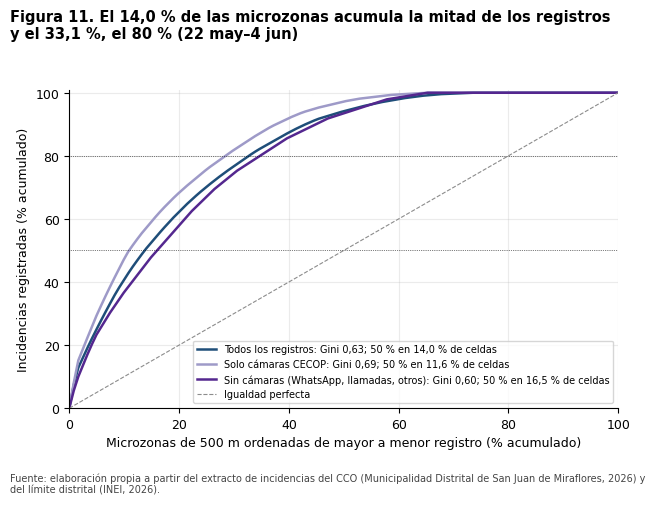

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig11_curva_concentracion.png')

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 5))
for nombre, datos, color, lab in [("tv", tv, AZUL, "Todos los registros"),
                                   ("cam", tv[tv.canal_reporte == "CAMARAS CECOP"], "#9E9AC8", "Solo cámaras CECOP"),
                                   ("sin", tv[tv.canal_reporte != "CAMARAS CECOP"], "#54278F", "Sin cámaras (WhatsApp, llamadas, otros)")]:
    r, fx, acum = concentracion(conteo_universo(datos, TAM))
    ax.plot(np.r_[0, fx] * 100, np.r_[0, acum] * 100, color=color, lw=1.8,
            label=f"{lab}: Gini {fmt(r['gini'], 2)}; 50 % en {fmt(r['pct_celdas_50'], 1)} % de celdas")
ax.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=0.8, label="Igualdad perfecta")
ax.axhline(50, color="k", lw=0.5, ls=":"); ax.axhline(80, color="k", lw=0.5, ls=":")
ax.set_xlabel(f"Microzonas de {TAM} m ordenadas de mayor a menor registro (% acumulado)")
ax.set_ylabel("Incidencias registradas (% acumulado)")
ax.legend(fontsize=7, loc="lower right"); eje_es(ax, "x", 0); eje_es(ax, "y", 0)
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
guardar_figura(fig, "fig11_curva_concentracion.png", 11,
               f"El {fmt(principal['pct_celdas_50'], 1)} % de las microzonas acumula la mitad de los registros\n"
               f"y el {fmt(principal['pct_celdas_80'], 1)} %, el 80 % (22 may–4 jun)", FUENTE_CCO_LIMITE)

In [9]:
alternativas = []
for _, r in comparacion.iterrows():
    motivos = []
    if not r.a_senal: motivos.append(f"poca señal para tres niveles (Alto {fmt(r.pct_alto_train, 1)} % en entrenamiento)")
    if not r.b_interpretable: motivos.append(f"celda demasiado grande para orientar patrullaje ({fmt(r.area_km2, 2)} km²)")
    if not r.c_manejable: motivos.append(f"{r.n_activas} celdas activas, fuera del rango 30–150")
    if not r.d_cobertura: motivos.append(f"cobertura {fmt(r.cobertura_tv_pct, 1)} % < 95 %")
    comentario = "Elegida: cumple los cuatro criterios" if r.cumple_todo else "Descartada: " + "; ".join(motivos)
    alternativas.append({"tamano_m": int(r.tamano_m), "pct_ceros": float(r.pct_ceros), "n_activas": int(r.n_activas), "comentario": comentario})
metricas = {"tamano_elegido_m": TAM, "origen_grilla": list(org), "n_activas": int(len(act)), "celdas_distrito": int(len(inter)),
            "comparacion": comparacion.drop(columns=[]).to_dict(orient="records"), "alternativas_evaluadas": alternativas,
            "he2": he2, "he2_resultado": resultado_he2, "he2_spearman_train_valid": round(float(rho), 3),
            "he2_solape_top10": round(float(solape), 1), "he2_k_top10": k,
            "cobertura_train_pct": round(float((~sin_mz[(df.fecha >= TR_INI) & (df.fecha <= TR_FIN)]).mean() * 100), 1),
            "cobertura_valid_pct": round(float((~sin_mz[(df.fecha >= VA_INI) & (df.fecha <= VA_FIN)]).mean() * 100), 1)}
(DATOS / "metricas_espacial.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
for a in alternativas: print(a)

{'tamano_m': 300, 'pct_ceros': 84.7, 'n_activas': 176, 'comentario': 'Descartada: poca señal para tres niveles (Alto 3,6 % en entrenamiento); 176 celdas activas, fuera del rango 30–150'}
{'tamano_m': 500, 'pct_ceros': 72.4, 'n_activas': 86, 'comentario': 'Elegida: cumple los cuatro criterios'}
{'tamano_m': 750, 'pct_ceros': 58.1, 'n_activas': 45, 'comentario': 'Descartada: celda demasiado grande para orientar patrullaje (0,56 km²)'}
{'tamano_m': 1000, 'pct_ceros': 50.8, 'n_activas': 30, 'comentario': 'Descartada: celda demasiado grande para orientar patrullaje (1,00 km²)'}


## Hallazgos

Cifras exactas en las salidas de arriba y en `datos/metricas_espacial.json`.

1. **Microzona elegida: grilla de 500 m** (0,25 km², ≈ 5 × 5 cuadras), la única opción que cumple los cuatro criterios fijados de antemano.
   300 m deja solo 3,6 % de celdas-turno en Alto y 176 celdas activas; 750 y 1 000 m dan mejor balance de clases (Alto 19,7 % y 16,9 %), pero
   con celdas de 0,56 y 1 km², demasiado grandes para orientar un patrullaje.
2. **Microzonas activas:** 86 de las 121 celdas de 500 m que intersecan el distrito registran ≥ 1 incidencia en entrenamiento (22–31 may).
   Cubren el 100 % de los registros de entrenamiento y el 98,3 % de los de validación; los registros en celdas no activas no entran al modelo.
3. **Ceros:** el 72,4 % de las celdas-turno (22 may–4 jun) no registra incidencias: la clase Bajo será mayoritaria.
4. **HE2 se sostiene (exploratorio):** el 14,0 % de las celdas acumula el 50 % de los registros y el 33,1 % acumula el 80 % (Gini 0,63).
   La conclusión se mantiene con 300 y 750 m y por separado en entrenamiento y validación; la ordenación de celdas es estable
   (Spearman 0,82 entre entrenamiento y validación; 62 % de solape del 10 % superior) y la concentración persiste en los registros
   que no provienen de cámaras (Gini 0,60; 50 % en el 16,5 % de las celdas).
5. **Cautela:** la concentración describe **dónde registra el CCO** (cámaras y patrullaje), no dónde ocurre el delito; no debe usarse para
   etiquetar zonas como peligrosas.